# 09 — Zonal Classification and Region Comparison

## Objective

This notebook trains **Logistic Regression, Random Forest, and XGBoost** on radiomic features extracted separately from the peripheral zone (PZ), transition zone (TZ), and their concatenation (PZ + TZ).

The same patient-level split and source labels used in notebooks 06–07 are maintained. For fair cohort comparisons, the original whole-gland feature table is restricted to the **identical cases** available in the zonal feature table.

**Interpretation warning:** The whole-gland baseline uses U-Net-predicted masks; PZ/TZ features use available anatomical reference masks. Therefore region and mask provenance are confounded. This study is an exploratory comparison, not proof of a zonal segmentation advantage.

## 1. Environment and Paths

Run from `notebooks/`. This notebook uses the classification environment (scikit-learn, XGBoost, matplotlib, joblib), not PyRadiomics.

In [1]:
from pathlib import Path
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().parent
RANDOM_STATE = 42
features_dir = PROJECT_ROOT / "src" / "data" / "features"
zonal_path = features_dir / "zonal_t2w_radiomics.csv"
whole_gland_path = features_dir / "whole_gland_t2w_radiomics.csv"
clinical_path = PROJECT_ROOT / "src" / "data" / "raw" / "picai_labels" / "clinical_information" / "marksheet.csv"
splits_path = PROJECT_ROOT / "src" / "data" / "processed" / "splits" / "patient_splits.csv"
results_dir = PROJECT_ROOT / "results" / "zonal_classification"
results_dir.mkdir(parents=True, exist_ok=True)
for path in [zonal_path, whole_gland_path, clinical_path, splits_path]:
    if not path.is_file():
        raise FileNotFoundError(f"Required file missing: {path}")
print("Zonal features:", zonal_path)
print("Whole-gland features:", whole_gland_path)

Zonal features: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\zonal_t2w_radiomics.csv
Whole-gland features: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\src\data\features\whole_gland_t2w_radiomics.csv


## 2. Load and Validate Source Tables

Retain patient/study identifiers as strings. Use only the `case_csPCa` outcome and previously saved split labels.

In [2]:
id_columns = ["patient_id", "study_id"]
dtypes = {"patient_id": str, "study_id": str}
zonal_df = pd.read_csv(zonal_path, dtype=dtypes)
whole_df = pd.read_csv(whole_gland_path, dtype=dtypes)
clinical_df = pd.read_csv(clinical_path, dtype=dtypes)
splits_df = pd.read_csv(splits_path, dtype=dtypes)
for name, table in [("Zonal", zonal_df), ("Whole gland", whole_df), ("Clinical", clinical_df), ("Splits", splits_df)]:
    if not set(id_columns).issubset(table.columns):
        raise ValueError(f"Missing case identifiers in {name}")
    if table.duplicated(id_columns).any():
        raise ValueError(f"Duplicate patient-study pair in {name}")

pz_columns = [col for col in zonal_df if col.startswith("pz__")]
tz_columns = [col for col in zonal_df if col.startswith("tz__")]
wg_columns = [col for col in whole_df if col not in id_columns]
if (len(pz_columns), len(tz_columns), len(wg_columns)) != (107, 107, 107):
    raise ValueError(f"Unexpected feature counts: PZ={len(pz_columns)}, TZ={len(tz_columns)}, WG={len(wg_columns)}")

# Inner join ensures every evaluated region has exactly the same cases.
cohort = zonal_df.merge(whole_df, on=id_columns, how="inner", validate="one_to_one", suffixes=("", "_wg"))
cohort = cohort.merge(clinical_df[id_columns + ["case_csPCa"]], on=id_columns, how="left", validate="one_to_one")
cohort = cohort.merge(splits_df[id_columns + ["split"]], on=id_columns, how="left", validate="one_to_one")
if cohort[["case_csPCa", "split"]].isna().any().any():
    raise ValueError("Missing outcome or split in common cohort")
cohort["split"] = cohort["split"].astype(str).str.lower().str.strip().replace({"validation": "val"})
target_mapping = {"YES": 1, "NO": 0, "TRUE": 1, "FALSE": 0, "1": 1, "0": 0}
cohort["target"] = cohort["case_csPCa"].astype(str).str.upper().str.strip().map(target_mapping)
if cohort["target"].isna().any():
    raise ValueError("Unknown clinical target")
cohort["target"] = cohort["target"].astype(int)
if not set(cohort["split"]).issubset({"train", "val", "test"}):
    raise ValueError("Unknown saved split")
print("Zonal cases:", len(zonal_df), "Whole-gland cases:", len(whole_df), "Shared cohort:", len(cohort))
display(pd.crosstab(cohort["split"], cohort["target"]))
if cohort["split"].nunique() != 3 or cohort.groupby("split")["target"].nunique().min() < 2:
    raise ValueError("Each of train/val/test must contain both classes")

# Join adds '_wg' suffix only to overlapping feature names.
whole_columns_in_cohort = [col if col not in zonal_df.columns else f"{col}_wg" for col in wg_columns]
feature_groups = {
    "PZ": pz_columns,
    "TZ": tz_columns,
    "PZ + TZ": pz_columns + tz_columns,
    "Whole gland (predicted mask)": whole_columns_in_cohort,
}
for name, columns in feature_groups.items():
    if not set(columns).issubset(cohort.columns):
        raise ValueError(f"Missing features for {name}")
    cohort[columns] = cohort[columns].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if cohort[columns].isna().all(axis=0).any():
        raise ValueError(f"Entirely missing feature column in {name}")
print("Features and shared cohort verified")

Zonal cases: 1500 Whole-gland cases: 1500 Shared cohort: 1500


C:\Users\Luiz Trindade\AppData\Local\Temp\ipykernel_4068\76083455.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cohort["target"] = cohort["case_csPCa"].astype(str).str.upper().str.strip().map(target_mapping)


target,0,1
split,,
test,162,63
train,752,298
val,161,64


Features and shared cohort verified


## 3. Prepare Training, Validation and Test Sets

Do not regenerate splits or fit preprocessing on validation/test data. Candidate selection is based only on validation ROC-AUC.

In [3]:
datasets = {}
for region_name, columns in feature_groups.items():
    datasets[region_name] = {}
    for split_name in ["train", "val", "test"]:
        subset = cohort.loc[cohort["split"] == split_name]
        datasets[region_name][split_name] = (
            subset[columns].to_numpy(dtype=float),
            subset["target"].to_numpy(dtype=int),
        )
for region_name, partitions in datasets.items():
    print(region_name, {key: value[0].shape for key, value in partitions.items()})
cohort[id_columns + ["split", "target"]].to_csv(results_dir / "shared_cohort.csv", index=False)

PZ {'train': (1050, 107), 'val': (225, 107), 'test': (225, 107)}
TZ {'train': (1050, 107), 'val': (225, 107), 'test': (225, 107)}
PZ + TZ {'train': (1050, 214), 'val': (225, 214), 'test': (225, 214)}
Whole gland (predicted mask) {'train': (1050, 107), 'val': (225, 107), 'test': (225, 107)}


## 4. Candidate Models

The candidate ranges are deliberately modest to keep the experiment reproducible. Logistic Regression scales its inputs inside the training-only pipeline; tree models use median imputation. The class weight for XGBoost is calculated from **training cases only**.

In [4]:
y_train = datasets["PZ"]["train"][1]
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
positive_weight = negative_count / positive_count

def make_candidates():
    logistic = [
        (f"C={C}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("classifier", LogisticRegression(
                C=C, class_weight="balanced", max_iter=3000,
                solver="liblinear", random_state=RANDOM_STATE,
            )),
        ])) for C in [0.01, 0.1, 1.0, 10.0]
    ]
    forest = [
        (f"trees={trees},depth={depth},leaf={leaf}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", RandomForestClassifier(
                n_estimators=trees, max_depth=depth,
                min_samples_leaf=leaf, class_weight="balanced",
                random_state=RANDOM_STATE, n_jobs=-1,
            )),
        ])) for trees in [150, 300] for depth in [5, None] for leaf in [2, 5]
    ]
    xgboost = [
        (f"trees={trees},depth={depth}", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("classifier", XGBClassifier(
                n_estimators=trees, max_depth=depth,
                learning_rate=0.03, min_child_weight=10,
                reg_alpha=0.5, reg_lambda=10,
                subsample=0.8, colsample_bytree=0.8,
                scale_pos_weight=positive_weight,
                objective="binary:logistic", eval_metric="logloss",
                random_state=RANDOM_STATE, tree_method="hist",
                n_jobs=-1,
            )),
        ])) for trees in [100, 150] for depth in [2, 3]
    ]
    return {"Logistic Regression": logistic, "Random Forest": forest, "XGBoost": xgboost}

print("Training class counts:", negative_count, positive_count)
print("XGBoost class weight:", positive_weight)
print("Candidate counts:", {key: len(val) for key, val in make_candidates().items()})

Training class counts: 752 298
XGBoost class weight: 2.523489932885906
Candidate counts: {'Logistic Regression': 4, 'Random Forest': 8, 'XGBoost': 4}


## 5. Model Selection on Validation

Each region is evaluated using independently selected hyperparameters; no test scores are used to select candidate models.

In [5]:
selection_rows = []
selected = {}
for region_name, partitions in datasets.items():
    X_train, y_train = partitions["train"]
    X_val, y_val = partitions["val"]
    for model_name, candidates in make_candidates().items():
        best_auc = -np.inf
        for configuration, candidate in candidates:
            start = time.perf_counter()
            candidate.fit(X_train, y_train)
            elapsed = time.perf_counter() - start
            scores = candidate.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, scores)
            selection_rows.append({
                "region": region_name, "model": model_name,
                "configuration": configuration, "validation_roc_auc": auc,
                "training_seconds": elapsed,
            })
            if auc > best_auc:
                best_auc = auc
                selected[(region_name, model_name)] = {
                    "model": candidate, "configuration": configuration,
                    "validation_roc_auc": auc,
                    "training_seconds": elapsed,
                }
        print(region_name, model_name, "best validation ROC-AUC:", round(best_auc, 4))
selection_df = pd.DataFrame(selection_rows)
display(selection_df.sort_values("validation_roc_auc", ascending=False).head(20))

PZ Logistic Regression best validation ROC-AUC: 0.6661
PZ Random Forest best validation ROC-AUC: 0.7287
PZ XGBoost best validation ROC-AUC: 0.6687
TZ Logistic Regression best validation ROC-AUC: 0.7054
TZ Random Forest best validation ROC-AUC: 0.7114
TZ XGBoost best validation ROC-AUC: 0.6985
PZ + TZ Logistic Regression best validation ROC-AUC: 0.7167
PZ + TZ Random Forest best validation ROC-AUC: 0.7364
PZ + TZ XGBoost best validation ROC-AUC: 0.7197
Whole gland (predicted mask) Logistic Regression best validation ROC-AUC: 0.7188
Whole gland (predicted mask) Random Forest best validation ROC-AUC: 0.7077
Whole gland (predicted mask) XGBoost best validation ROC-AUC: 0.7125


,region,model,configuration,validation_roc_auc,training_seconds
39,PZ + TZ,Random Forest,"trees=150,depth=None,leaf=5",0.736413,0.351039
43,PZ + TZ,Random Forest,"trees=300,depth=None,leaf=5",0.730202,0.673309
36,PZ + TZ,Random Forest,"trees=150,depth=5,leaf=2",0.730008,0.359406
6,PZ,Random Forest,"trees=150,depth=None,leaf=2",0.728746,0.401504
42,PZ + TZ,Random Forest,"trees=300,depth=None,leaf=2",0.728455,0.729294
37,PZ + TZ,Random Forest,"trees=150,depth=5,leaf=5",0.727096,0.344683
41,PZ + TZ,Random Forest,"trees=300,depth=5,leaf=5",0.725835,0.625207
40,PZ + TZ,Random Forest,"trees=300,depth=5,leaf=2",0.725738,0.779184
38,PZ + TZ,Random Forest,"trees=150,depth=None,leaf=2",0.720206,0.387877
47,PZ + TZ,XGBoost,"trees=150,depth=3",0.719720,0.700007


### 5.1 Validation-Only Thresholds

Select the Youden threshold independently for each selected region/model combination.

In [6]:
def youden_threshold(y_true, scores):
    fpr, tpr, thresholds = roc_curve(y_true, scores)
    valid = np.isfinite(thresholds)
    if not valid.any():
        raise ValueError("No finite threshold candidates")
    return float(thresholds[valid][np.argmax(tpr[valid] - fpr[valid])])

for (region_name, model_name), info in selected.items():
    X_val, y_val = datasets[region_name]["val"]
    val_scores = info["model"].predict_proba(X_val)[:, 1]
    info["threshold"] = youden_threshold(y_val, val_scores)
    print(region_name, model_name, "threshold:", round(info["threshold"], 5))

PZ Logistic Regression threshold: 0.42911
PZ Random Forest threshold: 0.38644
PZ XGBoost threshold: 0.41521
TZ Logistic Regression threshold: 0.51835
TZ Random Forest threshold: 0.56252
TZ XGBoost threshold: 0.56585
PZ + TZ Logistic Regression threshold: 0.45343
PZ + TZ Random Forest threshold: 0.42466
PZ + TZ XGBoost threshold: 0.41524
Whole gland (predicted mask) Logistic Regression threshold: 0.46979
Whole gland (predicted mask) Random Forest threshold: 0.50353
Whole gland (predicted mask) XGBoost threshold: 0.47866


## 6. Final Test Evaluation

**Execute only after** model/threshold selection has been frozen. Results from this test set must not be used to revise the candidate grids.

In [7]:
def evaluate_predictions(y_true, scores, threshold):
    predicted = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    return {
        "roc_auc": roc_auc_score(y_true, scores),
        "pr_auc": average_precision_score(y_true, scores),
        "sensitivity": recall_score(y_true, predicted, zero_division=0),
        "specificity": float(tn / (tn + fp)),
        "precision": precision_score(y_true, predicted, zero_division=0),
        "f1_score": f1_score(y_true, predicted, zero_division=0),
        "accuracy": accuracy_score(y_true, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_true, predicted),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

metrics_rows = []
prediction_frames = []
for (region_name, model_name), info in selected.items():
    X_test, y_test = datasets[region_name]["test"]
    scores = info["model"].predict_proba(X_test)[:, 1]
    metrics_rows.append({
        "region": region_name, "model": model_name,
        "configuration": info["configuration"],
        "validation_roc_auc": info["validation_roc_auc"],
        "threshold": info["threshold"],
        **evaluate_predictions(y_test, scores, info["threshold"]),
    })
    test_cases = cohort.loc[cohort["split"] == "test", id_columns].copy()
    test_cases["region"] = region_name
    test_cases["model"] = model_name
    test_cases["target"] = y_test
    test_cases["score"] = scores
    test_cases["prediction"] = (scores >= info["threshold"]).astype(int)
    prediction_frames.append(test_cases)
metrics_df = pd.DataFrame(metrics_rows)
predictions_df = pd.concat(prediction_frames, ignore_index=True)
display(metrics_df[["region", "model", "roc_auc", "pr_auc", "sensitivity", "specificity", "f1_score", "balanced_accuracy"]].round(4))

,region,model,roc_auc,pr_auc,sensitivity,specificity,f1_score,balanced_accuracy
0,PZ,Logistic Regression,0.7374,0.5208,0.6984,0.6728,0.5500,0.6856
1,PZ,Random Forest,0.7139,0.5137,0.6984,0.6481,0.5366,0.6733
2,PZ,XGBoost,0.7109,0.5081,0.6984,0.5864,0.5057,0.6424
3,TZ,Logistic Regression,0.6664,0.4283,0.4444,0.7160,0.4088,0.5802
4,TZ,Random Forest,0.6346,0.3972,0.3810,0.7840,0.3934,0.5825
5,TZ,XGBoost,0.6464,0.4156,0.4286,0.7840,0.4320,0.6063
6,PZ + TZ,Logistic Regression,0.7213,0.4871,0.7143,0.6049,0.5233,0.6596
7,PZ + TZ,Random Forest,0.6720,0.4640,0.5873,0.6358,0.4654,0.6116
8,PZ + TZ,XGBoost,0.6859,0.4586,0.6508,0.5679,0.4713,0.6093
9,Whole gland (predicted mask),Logistic Regression,0.6683,0.4762,0.6508,0.6049,0.4881,0.6279


## 7. Visualizations

One ROC and PR curve per region, comparing the three classifiers on the shared test cohort.

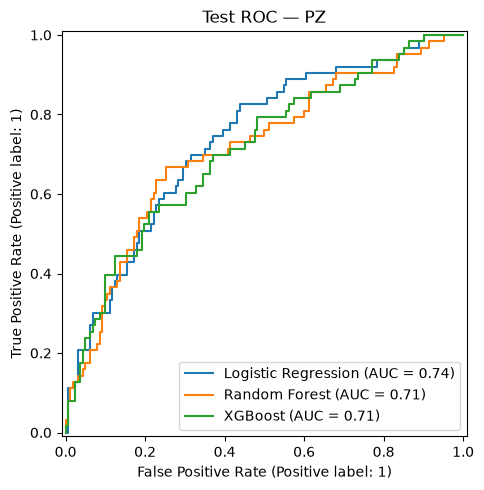

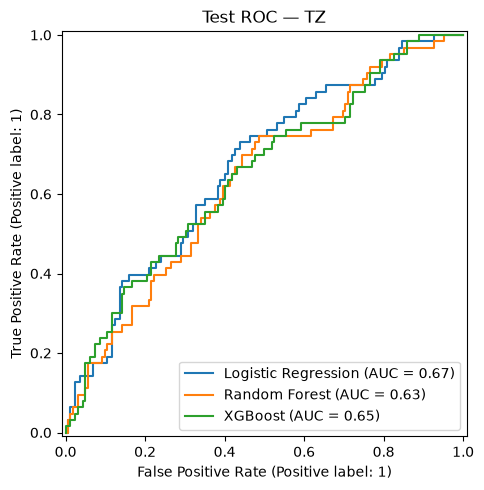

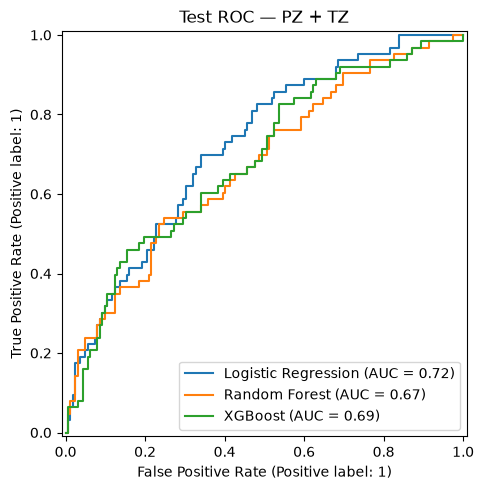

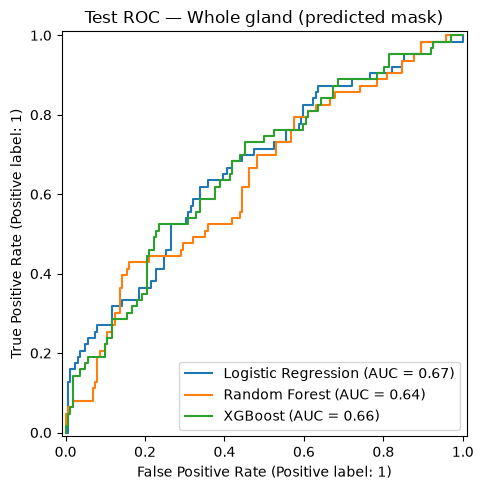

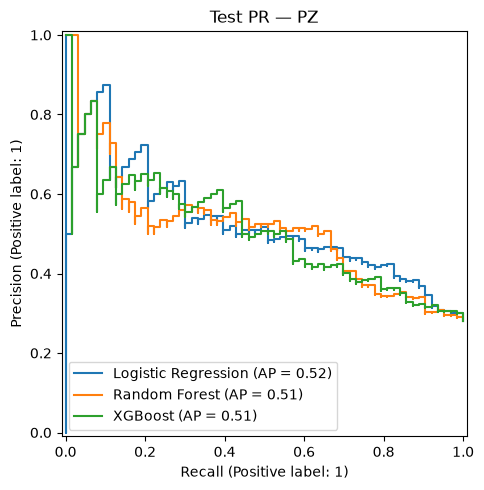

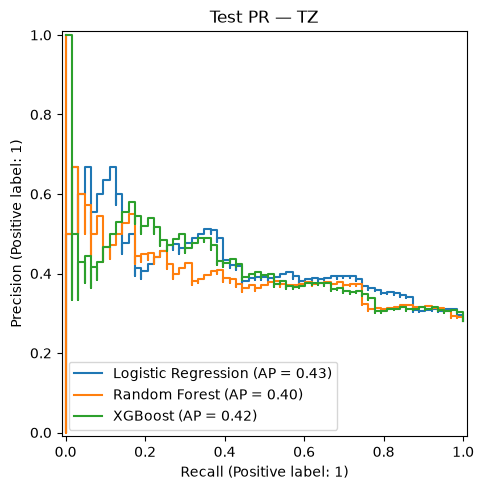

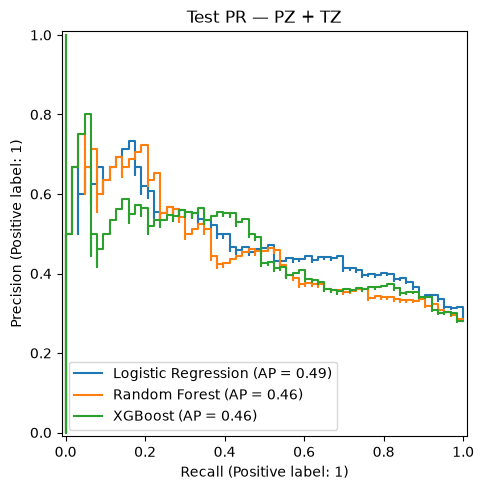

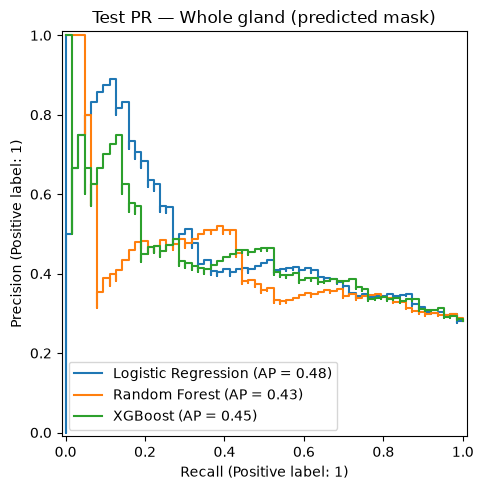

In [8]:
for region_name in feature_groups:
    fig, ax = plt.subplots(figsize=(7, 5))
    for model_name in make_candidates():
        model = selected[(region_name, model_name)]["model"]
        X_test, y_test = datasets[region_name]["test"]
        RocCurveDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=model_name, ax=ax)
    ax.set_title(f"Test ROC — {region_name}")
    fig.tight_layout()
    fig.savefig(results_dir / f"roc_{region_name.lower().replace(' ', '_').replace('+', 'plus')}.png", dpi=160)
    plt.show()

for region_name in feature_groups:
    fig, ax = plt.subplots(figsize=(7, 5))
    for model_name in make_candidates():
        model = selected[(region_name, model_name)]["model"]
        X_test, y_test = datasets[region_name]["test"]
        PrecisionRecallDisplay.from_predictions(y_test, model.predict_proba(X_test)[:, 1], name=model_name, ax=ax)
    ax.set_title(f"Test PR — {region_name}")
    fig.tight_layout()
    fig.savefig(results_dir / f"pr_{region_name.lower().replace(' ', '_').replace('+', 'plus')}.png", dpi=160)
    plt.show()

## 8. Save Models and Experimental Results

All files are saved separately from the notebooks 06–07 experiments.

In [9]:
selection_df.to_csv(results_dir / "validation_model_selection.csv", index=False)
metrics_df.to_csv(results_dir / "test_metrics.csv", index=False)
predictions_df.to_csv(results_dir / "test_predictions.csv", index=False)
for (region_name, model_name), info in selected.items():
    slug = (region_name + "_" + model_name).lower().replace(" ", "_").replace("+", "plus").replace("(", "").replace(")", "")
    joblib.dump(info["model"], results_dir / f"{slug}.joblib")
metadata = {
    "random_state": RANDOM_STATE,
    "zonal_features": str(zonal_path),
    "whole_gland_features": str(whole_gland_path),
    "clinical_labels": str(clinical_path),
    "splits": str(splits_path),
    "shared_cohort_cases": len(cohort),
    "regions": {name: len(columns) for name, columns in feature_groups.items()},
    "selection_metric": "validation_roc_auc",
    "threshold_method": "validation_youden_index",
    "mask_provenance": "PZ/TZ reference masks vs whole-gland predicted masks",
    "selected_models": {
        f"{region_name} / {model_name}": {
            "configuration": info["configuration"],
            "validation_roc_auc": float(info["validation_roc_auc"]),
            "threshold": float(info["threshold"]),
            "training_seconds": float(info["training_seconds"]),
        } for (region_name, model_name), info in selected.items()
    },
}
with (results_dir / "experiment_config.json").open("w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)
print("Results saved:", results_dir)

Results saved: c:\Users\Luiz Trindade\Documents\penguin-adventure\TCC_II\results\zonal_classification


## 9. Interpretation and Limitations

- **Same cases** are used for all four feature representations. If masks are missing, the cohort is smaller than the original 1,500 examinations.
- Clinical labels are case-level; this is not lesion localization.
- Anatomical zonal masks and whole-gland predictions originate from different segmentation procedures. Therefore changes in metrics cannot be attributed solely to the region of interest.
- Hyperparameters and thresholds were selected on the validation partition; testing is a final evaluation only.
- The original full-cohort scores from notebook 07 must **not** be compared directly as if they came from this potentially reduced cohort. Use the whole-gland results recomputed here.
- Reusing an already inspected test set for new exploratory hypotheses limits confirmatory claims. Report these experiments as exploratory.